In [18]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

pd.set_option('display.max_columns', None)

In [19]:
df = pd.read_csv('/content/Ecommerce_cleaned (1).csv')

print("Dataset Shape:", df.shape)

df.head()

Dataset Shape: (25000, 29)


,customer_id,session_id,visit_date,device_type,user_type,marketing_channel,product_id,product_category,unit_price,quantity,discount_percent,discount_amount,revenue,pages_viewed,time_on_site_sec,added_to_cart,purchased,cart_abandoned,rating,review_text,review_helpful_votes,payment_method,visit_day,visit_month,visit_weekday,visit_season,session_duration_bucket,revenue_normalized,location
0,1803,0,2024-11-28,2,1,2,894,6,651.57,1,20,130.31,0.00,21,965,1,0,1,4,1,0,1,28,11,3,0,Long,0.000000,209
1,7964,1,2024-09-25,2,0,4,844,2,945.27,4,15,567.16,0.00,21,1158,0,0,0,4,1,0,2,25,9,2,0,Long,0.000000,213
2,6890,2,2024-05-31,1,1,0,865,0,400.44,4,0,0.00,0.00,19,710,1,0,1,4,1,0,2,31,5,4,1,Short,0.000000,10
3,4949,3,2024-01-30,1,0,2,851,3,1268.54,2,5,126.85,2410.23,19,1674,1,1,0,4,10,4,1,30,1,1,3,Very Long,0.305504,46
4,4896,4,2024-02-25,1,1,5,794,3,880.81,3,0,0.00,0.00,13,427,1,0,1,4,1,0,1,25,2,6,3,Very Short,0.000000,118


In [20]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 25000 entries, 0 to 24999
Data columns (total 29 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              25000 non-null  int64  
 1   session_id               25000 non-null  int64  
 2   visit_date               25000 non-null  object 
 3   device_type              25000 non-null  int64  
 4   user_type                25000 non-null  int64  
 5   marketing_channel        25000 non-null  int64  
 6   product_id               25000 non-null  int64  
 7   product_category         25000 non-null  int64  
 8   unit_price               25000 non-null  float64
 9   quantity                 25000 non-null  int64  
 10  discount_percent         25000 non-null  int64  
 11  discount_amount          25000 non-null  float64
 12  revenue                  25000 non-null  float64
 13  pages_viewed             25000 non-null  int64  
 14  time_on_site_sec      

In [21]:
customer_df = df.groupby('customer_id').agg(
    total_sessions=('session_id', 'nunique'),
    total_purchases=('purchased', 'sum'),
    total_revenue=('revenue', 'sum'),
    total_quantity=('quantity', 'sum'),
    avg_session_duration=('time_on_site_sec', 'mean'),
    avg_pages_viewed=('pages_viewed', 'mean'),
    total_cart_adds=('added_to_cart', 'sum')
).reset_index()

customer_df.head()

,customer_id,total_sessions,total_purchases,total_revenue,total_quantity,avg_session_duration,avg_pages_viewed,total_cart_adds
0,1000,2,1,1228.72,7,1014.000000,17.500000,2
1,1001,1,0,0.00,4,996.000000,15.000000,0
2,1002,3,0,0.00,8,313.666667,8.333333,2
3,1003,3,1,1681.96,9,695.333333,5.666667,1
4,1004,3,0,0.00,5,923.666667,12.333333,1


In [22]:
print("Customer Dataset Shape:", customer_df.shape)

print("\nMissing Values:")
print(customer_df.isnull().sum())

print("\nStatistical Summary:")
customer_df.describe().round(2)

Customer Dataset Shape: (8442, 8)

Missing Values:
customer_id             0
total_sessions          0
total_purchases         0
total_revenue           0
total_quantity          0
avg_session_duration    0
avg_pages_viewed        0
total_cart_adds         0
dtype: int64

Statistical Summary:


,customer_id,total_sessions,total_purchases,total_revenue,total_quantity,avg_session_duration,avg_pages_viewed,total_cart_adds
count,8442.00,8442.00,8442.00,8442.00,8442.00,8442.00,8442.00,8442.00
mean,5485.12,2.96,0.67,1198.31,7.37,906.73,12.54,1.91
std,2597.21,1.55,0.80,1867.86,4.33,354.85,4.65,1.31
min,1000.00,1.00,0.00,0.00,1.00,10.00,1.00,0.00
25%,3239.25,2.00,0.00,0.00,4.00,672.27,9.50,1.00
50%,5479.50,3.00,0.00,0.00,7.00,905.78,12.50,2.00
75%,7730.75,4.00,1.00,1828.96,10.00,1140.19,15.67,3.00
max,9998.00,11.00,5.00,15955.15,32.00,1794.00,24.00,10.00


In [23]:
features = [
    'total_sessions',
    'total_purchases',
    'total_revenue',
    'total_quantity',
    'avg_session_duration',
    'avg_pages_viewed',
    'total_cart_adds'
]

X = customer_df[features]

print("Selected Features:")
print(X.head())

print("\nFeature Shape:", X.shape)

Selected Features:
   total_sessions  total_purchases  total_revenue  total_quantity  \
0               2                1        1228.72               7   
1               1                0           0.00               4   
2               3                0           0.00               8   
3               3                1        1681.96               9   
4               3                0           0.00               5   

   avg_session_duration  avg_pages_viewed  total_cart_adds  
0           1014.000000         17.500000                2  
1            996.000000         15.000000                0  
2            313.666667          8.333333                2  
3            695.333333          5.666667                1  
4            923.666667         12.333333                1  

Feature Shape: (8442, 7)


In [24]:
print("Missing Values:")
print(X.isnull().sum())

print("\nOutlier Count:")

for col in features:
    Q1 = X[col].quantile(0.25)
    Q3 = X[col].quantile(0.75)

    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    outliers = ((X[col] < lower) | (X[col] > upper)).sum()

    print(f"{col}: {outliers}")

Missing Values:
total_sessions          0
total_purchases         0
total_revenue           0
total_quantity          0
avg_session_duration    0
avg_pages_viewed        0
total_cart_adds         0
dtype: int64

Outlier Count:
total_sessions: 71
total_purchases: 236
total_revenue: 590
total_quantity: 95
avg_session_duration: 0
avg_pages_viewed: 0
total_cart_adds: 30


In [25]:
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X)

X_scaled = pd.DataFrame(
    X_scaled,
    columns=features
)

print("Scaled Dataset:")
print(X_scaled.head())

print("\nScaled Shape:", X_scaled.shape)

Scaled Dataset:
   total_sessions  total_purchases  total_revenue  total_quantity  \
0       -0.621451         0.417552       0.016279       -0.085752   
1       -1.267865        -0.829784      -0.641583       -0.779163   
2        0.024962        -0.829784      -0.641583        0.145385   
3        0.024962         0.417552       0.258946        0.376522   
4        0.024962        -0.829784      -0.641583       -0.548026   

   avg_session_duration  avg_pages_viewed  total_cart_adds  
0              0.302309          1.067164         0.069480  
1              0.251581          0.529304        -1.459985  
2             -1.671400         -0.904988         0.069480  
3             -0.595771         -1.478706        -0.695253  
4              0.047728         -0.044413        -0.695253  

Scaled Shape: (8442, 7)


In [26]:
wcss = []

for k in range(1, 11):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    kmeans.fit(X_scaled)
    wcss.append(kmeans.inertia_)

print("WCSS Values:", wcss)

WCSS Values: [59094.00000000025, 40858.20463519424, 35754.14631648382, 31365.833738127083, 28291.432371499428, 25633.189412056498, 23876.24801471821, 22407.631818797192, 21236.568506777698, 20403.345648183113]


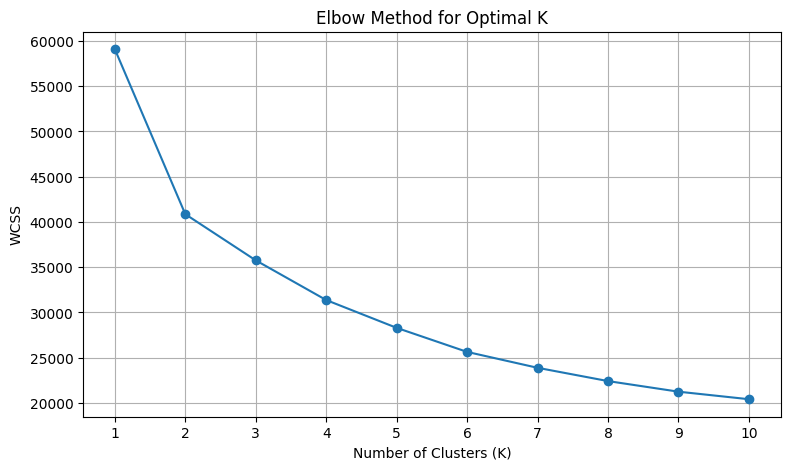

In [27]:
plt.figure(figsize=(9, 5))

plt.plot(range(1, 11), wcss, marker='o')

plt.title('Elbow Method for Optimal K')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('WCSS')
plt.xticks(range(1, 11))
plt.grid(True)

plt.show()

In [28]:
silhouette_scores = []

for k in range(2, 11):
    kmeans = KMeans(
        n_clusters=k,
        init='k-means++',
        random_state=42,
        n_init=10
    )

    labels = kmeans.fit_predict(X_scaled)

    score = silhouette_score(X_scaled, labels)

    silhouette_scores.append(score)

    print(f"K = {k}, Silhouette Score = {score:.4f}")

K = 2, Silhouette Score = 0.2872
K = 3, Silhouette Score = 0.1880
K = 4, Silhouette Score = 0.1841
K = 5, Silhouette Score = 0.1885
K = 6, Silhouette Score = 0.1866
K = 7, Silhouette Score = 0.1861
K = 8, Silhouette Score = 0.1789
K = 9, Silhouette Score = 0.1805
K = 10, Silhouette Score = 0.1797


In [29]:
optimal_k = 3

kmeans = KMeans(
    n_clusters=optimal_k,
    init='k-means++',
    random_state=42,
    n_init=10
)

customer_df['Cluster'] = kmeans.fit_predict(X_scaled)

print("K-Means model trained successfully!")

K-Means model trained successfully!


Customers in Each Cluster:
Cluster
0    1422
1    4244
2    2776
Name: count, dtype: int64


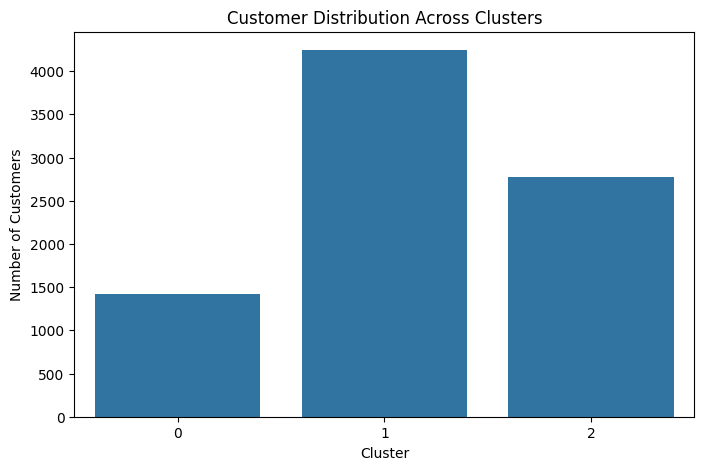

In [30]:
cluster_counts = customer_df['Cluster'].value_counts().sort_index()

print("Customers in Each Cluster:")
print(cluster_counts)

plt.figure(figsize=(8, 5))
sns.barplot(
    x=cluster_counts.index,
    y=cluster_counts.values
)

plt.title("Customer Distribution Across Clusters")
plt.xlabel("Cluster")
plt.ylabel("Number of Customers")
plt.show()

In [31]:
cluster_analysis = customer_df.groupby('Cluster')[features].mean().round(2)

print("Customer Segment Analysis:")
display(cluster_analysis)

Customer Segment Analysis:


,total_sessions,total_purchases,total_revenue,total_quantity,avg_session_duration,avg_pages_viewed,total_cart_adds
Cluster,,,,,,,
0,4.64,1.91,4203.72,11.97,921.19,12.60,3.47
1,1.79,0.30,465.64,4.21,914.93,12.54,1.00
2,3.89,0.59,778.92,9.85,886.80,12.51,2.49


In [32]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

pca_df = pd.DataFrame({
    'PCA1': X_pca[:, 0],
    'PCA2': X_pca[:, 1],
    'Cluster': customer_df['Cluster']
})

print("Explained Variance Ratio:", pca.explained_variance_ratio_)
print("Total Explained Variance:",
      pca.explained_variance_ratio_.sum())

Explained Variance Ratio: [0.46935006 0.15649654]
Total Explained Variance: 0.6258465973659422


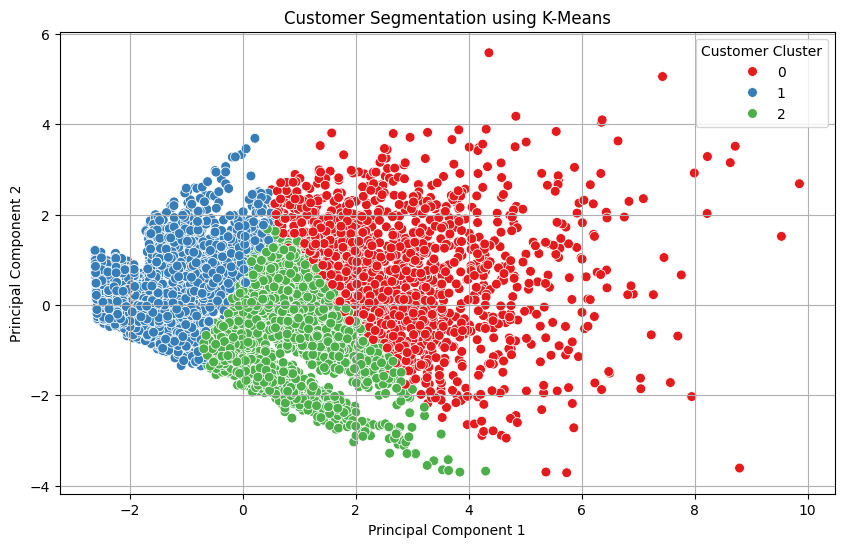

In [33]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=pca_df,
    x='PCA1',
    y='PCA2',
    hue='Cluster',
    palette='Set1',
    s=50
)

plt.title('Customer Segmentation using K-Means')
plt.xlabel('Principal Component 1')
plt.ylabel('Principal Component 2')
plt.legend(title='Customer Cluster')
plt.grid(True)
plt.show()

In [34]:
cluster_analysis = customer_df.groupby('Cluster')[features].mean()

# Rank clusters by average revenue
revenue_ranking = cluster_analysis['total_revenue'].sort_values(
    ascending=False
)

print("Cluster Revenue Ranking:")
print(revenue_ranking)

Cluster Revenue Ranking:
Cluster
0    4203.718179
2     778.924863
1     465.642410
Name: total_revenue, dtype: float64


In [37]:
import os
import joblib

os.makedirs('/content/models', exist_ok=True)
os.makedirs('/content/outputs', exist_ok=True)

# Save K-Means model and scaler
joblib.dump(kmeans, '/content/models/customer_segmentation_kmeans.joblib')
joblib.dump(scaler, '/content/models/customer_segmentation_scaler.joblib')

# Define final_report using our cluster analysis data
final_report = cluster_analysis

# Save customer segments and report
customer_df.to_csv(
    '/content/outputs/customer_segments.csv',
    index=False
)

final_report.to_csv(
    '/content/outputs/customer_segmentation_report.csv'
)

print("Model, scaler and segmentation reports saved successfully!")

Model, scaler and segmentation reports saved successfully!
